# v4 准备：14 维网格状态的占用测试（不跑 Infomap）

2026-11-08 讨论的 v4：在 v3 的状态 `(D_xy, Δz, θ_a, θ_b, speed_a, speed_b)` 上**全部加上**五个参数：

| 参数 | 维度 | 定义 |
|---|---|---|
| 相对方位角变化速度 `bearing_rate` | 1（配对量） | 两条鱼 pec 连线在水平面上旋转的角速度绝对值（rad/s），绕圈 |
| 接近速度 `approach` | 1（配对量） | 3D pec 距离变化率的负值（mm/s），正 = 靠近 |
| 转向速度 `turn_a`、`turn_b` | 2 | 每条鱼水平朝向（pec → head）的角速度绝对值（rad/s） |
| 身体弯曲 `bend_a`、`bend_b` | 2 | π − head-pec-tail 夹角（rad），0 = 身体笔直 |
| 俯仰角 `pitch_a`、`pitch_b` | 2 | pec → head 与水平面的夹角（rad），正 = 抬头 |

共 14 维，**保持网格分格**（不用 k-means、不用 PCA）。轨迹平滑做两版：不平滑、11 帧 Savitzky-Golay（二阶，只在连续片段内做，**不丢任何帧**，短于 11 帧的片段不平滑）。所有变化率和速度一样用中心差分 ±`RATE_HALF_WINDOW` 帧。

**这个 notebook 只回答一个问题**：14 维网格在不同分格方案下，状态会不会太稀（每个状态帧数太少），Infomap 还能不能跑。不跑 Infomap，不看任何标注。分格边界只用训练集（K_1_1、K_1_2、P_1_1、P_1_2）的分位数；测试集（K_1_3、P_1_3）只用来统计"落在训练集没见过的状态上"的帧比例。

**输出目录**：`<runs_dir>/behavior_features/outputs/20261108_pair_state14d_occupancy_v4/`。本 notebook 只给数值和图，不下结论。

## 参数

`SCHEMES` = 要比较的分格方案。每个变量的分格方式：
- `D_xy`：固定边界 `D_EDGES_MM` + 溢出格（你定的，所有方案相同）；
- `dz`、`approach`、`pitch`（有正负）：关于 0 对称，n 格时内边界取 |值| 的分位数（2 格 = 按正负分）；
- `theta`：等宽 n 格；`theta_abs` = 按 |θ| 在 [0, π] 上等宽分 n 格（不分左右：3 格 = 朝向 / 侧向 / 背向，2 格 = 朝向 / 背向）；
- `speed`、`bearing_rate`、`turn`、`bend`（非负）：2 格在第 75 百分位分开（"快 / 弯"= 最大的 25%），3 格在第 50、90 百分位分开（同 v3 速度）；
- `pitch` 的 2 格特殊处理：按 |pitch| 的第 75 百分位分为"平 / 倾斜"。

`v3` 方案只有 6 维（v3 原样），作为参照。A、B、C = 14 维；**D1–D4（2026-11-08 补测）= 压缩旧变量**：D_xy 不变，Δz 2 格，θ 4 格或按 |θ| 3 / 2 格，**去掉速度**，五个新参数全部保留（各 2 格，接近速度 2 或 3 格）。

In [1]:
# ============================== Parameters ==============================
from pathlib import Path

RUN_NAME = "20261108_pair_state14d_occupancy_v4"
OUTPUT_ROOT = None
TRAIN_EXPERIMENTS = ["20251225_K_1_1_FCMC", "20251225_K_1_2_FCMC", "20260112_P_1_1_FCMC", "20260113_P_1_2_FCMC"]
TEST_EXPERIMENTS = ["20251225_K_1_3_FCMC", "20260112_P_1_3_FCMC"]
UNITS = {"FM": [("F", "M1"), ("F", "M2")], "MM": [("M1", "M2"), ("M2", "M1")]}
DPI = 200
THUMB_WIDTH = 900

MIN_XY_MM = 1.0
SPEED_HALF_WINDOW = 3        # speed and all rates: central difference over +-3 frames (shorter near gaps)
SMOOTH_WINDOWS = [1, 11]     # 1 = no smoothing; 11 = Savitzky-Golay window (frames), order SG_ORDER
SG_ORDER = 2
D_EDGES_MM = [0, 5, 10, 15, 20, 30, 40]   # + overflow bin, all schemes
TAU_EDGES = 7                # lag (frames) for counting transition-graph edges (Infomap cost)

# bins per variable group; "v3" uses only the first six variables
SCHEMES = {
    "v3": {"dz": 4, "theta": 8, "speed": 3},
    "A":  {"dz": 2, "theta": 4, "speed": 2, "bearing_rate": 2, "approach": 3, "turn": 2, "bend": 2, "pitch": 2},
    "B":  {"dz": 4, "theta": 6, "speed": 3, "bearing_rate": 3, "approach": 3, "turn": 3, "bend": 3, "pitch": 3},
    "C":  {"dz": 4, "theta": 8, "speed": 3, "bearing_rate": 2, "approach": 3, "turn": 2, "bend": 2, "pitch": 2},
    # 2026-11-08: compress the old variables (D_xy fixed; speed dropped), all new variables kept
    "D1": {"dz": 2, "theta": 4, "bearing_rate": 2, "approach": 3, "turn": 2, "bend": 2, "pitch": 2},
    "D2": {"dz": 2, "theta": 4, "bearing_rate": 2, "approach": 2, "turn": 2, "bend": 2, "pitch": 2},
    "D3": {"dz": 2, "theta_abs": 3, "bearing_rate": 2, "approach": 3, "turn": 2, "bend": 2, "pitch": 2},
    "D4": {"dz": 2, "theta_abs": 2, "bearing_rate": 2, "approach": 2, "turn": 2, "bend": 2, "pitch": 2},
}
NONNEG_QUANTILES = {2: [0.75], 3: [0.5, 0.9]}
SIGNED_QUANTILE = 0.5        # signed variables with 3 bins: |value| quantile of the inner edges (middle = smaller half)
SPARSE_FRAMES = [10, 50]     # report the share of frames in states with fewer frames than these

PARAMETERS = {k: (str(v) if isinstance(v, Path) else v) for k, v in dict(globals()).items()
              if k.isupper() and k != "PARAMETERS"}
print(f"{len(PARAMETERS)} parameters; run {RUN_NAME}")

17 parameters; run 20261108_pair_state14d_occupancy_v4


## Setup（公共函数，不是分析步骤）

找仓库根目录、读路径配置、建输出目录。变量计算在 `scripts/analysis/pair_state4d.py`（`smooth_tracks`、`series_rate`、`extra_variables`，有单元测试）。

In [2]:
import os
import sys
import json
import time
import platform
import importlib

REPO = Path.cwd().resolve()
while not (REPO / "pyproject.toml").exists():
    if REPO.parent == REPO:
        raise RuntimeError("repository root (pyproject.toml) not found above the working directory")
    REPO = REPO.parent
os.chdir(REPO)
if str(REPO) not in sys.path:
    sys.path.insert(0, str(REPO))

import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image as IPImage, display

from scripts.analysis import microstate as M
from scripts.analysis import pose_states as S
from scripts.analysis import pair_state4d as P4
from scripts.analysis.behavior_dataset import resolve_roots

importlib.reload(P4)
_CONFIG, REVIEW_ROOT, _BF_ROOT = resolve_roots(None)
OUT_ROOT = Path(OUTPUT_ROOT) if OUTPUT_ROOT else Path(_BF_ROOT) / "outputs"
L = S.RunLayout(OUT_ROOT / RUN_NAME, dpi=DPI, thumb_width=THUMB_WIDTH)
ALL_EXPERIMENTS = list(TRAIN_EXPERIMENTS) + list(TEST_EXPERIMENTS)
SETS = {"train": list(TRAIN_EXPERIMENTS), "test": list(TEST_EXPERIMENTS)}


def _allow_listed(experiment, final):
    if experiment not in ALL_EXPERIMENTS:
        raise PermissionError(f"{experiment} is not in TRAIN_EXPERIMENTS / TEST_EXPERIMENTS")


M.require_access = _allow_listed
L.update_params("parameters", PARAMETERS)
L.update_params("run", {"run_name": RUN_NAME, "date": time.strftime("%Y-%m-%d %H:%M:%S"), "output_dir": str(L.root),
                        "review_root": str(REVIEW_ROOT), "paths_config": str(_CONFIG), "platform": platform.platform()})

VARS = list(P4.VARIABLES_SPEED) + list(P4.VARIABLES_EXTRA)   # 14 columns
GROUP = {"D_xy": "D_xy", "dz": "dz", "theta_a": "theta", "theta_b": "theta", "speed_a": "speed", "speed_b": "speed",
         "bearing_rate": "bearing_rate", "approach": "approach", "turn_a": "turn", "turn_b": "turn",
         "bend_a": "bend", "bend_b": "bend", "pitch_a": "pitch", "pitch_b": "pitch"}
SIGNED = {"dz", "approach", "pitch"}
ANGLE_VARS = ["theta_a", "theta_b", "bearing_rate", "turn_a", "turn_b"]   # undefined when fish are too close in XY


def copy_name(a, b):
    return f"{a}{b}"


COPIES = {u: [copy_name(a, b) for a, b in pairs] for u, pairs in UNITS.items()}
COPY_PAIR = {copy_name(a, b): (a, b) for pairs in UNITS.values() for a, b in pairs}
PAIR_COPIES = ["FM1", "FM2", "M1M2"]


def exp_short(e):
    g, t = M.parse_experiment(e)
    return f"{g}_{t}"


def scheme_vars(scheme):
    keys = set(SCHEMES[scheme]) | ({"theta"} if "theta_abs" in SCHEMES[scheme] else set())
    return [v for v in VARS if GROUP[v] == "D_xy" or GROUP[v] in keys]


def edges_for(scheme, train_vals):
    # Edges per variable of a scheme from train values (dict var -> 1-D array of finite train values).
    out = {}
    for v in scheme_vars(scheme):
        g = GROUP[v]
        if g == "D_xy":
            out[v] = np.concatenate([np.asarray(D_EDGES_MM, float), [np.inf]])
            continue
        if g == "theta" and "theta_abs" in SCHEMES[scheme]:
            out[v] = ("abs", np.linspace(0.0, np.pi, SCHEMES[scheme]["theta_abs"] + 1))
            continue
        n = SCHEMES[scheme][g]
        x = train_vals[v]
        if g == "theta":
            out[v] = np.linspace(-np.pi, np.pi, n + 1)
        elif g == "pitch" and n == 2:
            out[v] = ("abs", P4.quantile_edges(np.abs(x), NONNEG_QUANTILES[2]))
        elif g in SIGNED:
            if n == 2:
                out[v] = np.array([-np.inf, 0.0, np.inf])
            elif n == 3:
                q = float(np.quantile(np.abs(x), SIGNED_QUANTILE))
                out[v] = np.array([-np.inf, -q, q, np.inf])
            else:
                out[v] = P4.symmetric_dz_edges(np.abs(x), n)
        else:
            out[v] = P4.quantile_edges(x, NONNEG_QUANTILES[n])
    # the a and b variable of one fish group share edges (needed for the swap symmetry)
    for g in ("speed", "turn", "bend", "pitch"):
        a, b = f"{g}_a", f"{g}_b"
        if a in out:
            out[b] = out[a]
    return out


def bin_values(x, e):
    if isinstance(e, tuple):            # ("abs", edges): bin |x|
        return P4.digitize(np.abs(x), e[1])
    e = np.asarray(e, float)
    n = len(e) - 1
    if np.isinf(e[0]) and np.isinf(e[-1]) and n % 2 == 0 and np.allclose(e[1:-1], -e[1:-1][::-1]):
        return P4.digitize_symmetric(x, e)
    if n == 3 and np.isinf(e[0]) and np.isinf(e[-1]) and np.isclose(e[1], -e[2]):
        out = np.full(len(x), -1, np.int64)     # 3 symmetric bins: below -q / middle / above q
        f = np.isfinite(x)
        out[f] = np.where(x[f] < e[1], 0, np.where(x[f] > e[2], 2, 1))
        return out
    return P4.digitize(x, e)


def n_bins(e):
    return len(e[1]) - 1 if isinstance(e, tuple) else len(e) - 1


def encode(vals, contact, edges, cols):
    # Joint state: mixed radix over the scheme's variables; contact frames -> one extra state = product.
    widths = [n_bins(edges[v]) for v in cols]
    state = np.zeros(len(vals), np.int64)
    bad = np.zeros(len(vals), bool)
    scale = 1
    for v, w in zip(cols, widths):
        b = bin_values(vals[:, VARS.index(v)], edges[v])
        bad |= b < 0
        state += np.where(b < 0, 0, b) * scale
        scale *= w
    state[bad] = -1
    state[contact] = scale
    return state, int(scale) + 1


print("output folder", L.root)

output folder \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261108_pair_state14d_occupancy_v4


## Step 0 — 读数据，两版平滑，算 14 个变量

**做什么**：对 6 个实验读入审核后的 F/M1/M2 三节点 3D 坐标。对每个平滑版本（`SMOOTH_WINDOWS`）先平滑坐标，再对四个有序配对（FM1、FM2、M1M2、M2M1）算 14 个变量。帧的分类同 v3：
- **有状态**：14 个变量都有定义；
- **contact**：坐标都在，但两条鱼太近或鱼几乎竖直（水平长度 < `MIN_XY_MM`），角度类变量（θ、方位角变化速度、转向速度）无定义 → 一个单独的 contact 状态；
- **审核屏蔽**、**跟踪丢失**：没有状态；
- **其他未定义**：例如只缺尾点（身体弯曲算不出），单独统计。

**输出**：只在内存里（变量）；`data/00_gap_table__all__…__all.csv`（每个实验 × 配对 × 平滑版本的帧分类比例）。

In [3]:
# Step 0: load, smooth, 14 variables per ordered pair.
L.clear_log("00")
DATA = {}      # (window, experiment, copy) -> dict(vals float32 (T, 14), contact, ok)
gap_rows = []
for e in ALL_EXPERIMENTS:
    t0 = time.time()
    tr = M.load_trial(e, final=True)
    raw = np.array(tr["named"], dtype=np.float64, copy=True)
    blocked = np.asarray(tr["blocked"], dtype=bool)
    fps = float(tr["fps"])
    for w in SMOOTH_WINDOWS:
        nodes = P4.smooth_tracks(raw, w, SG_ORDER)
        speed = np.column_stack([P4.fish_speed(nodes[:, i, P4.PEC], fps, SPEED_HALF_WINDOW) for i in range(3)])
        for cp, (a, b) in COPY_PAIR.items():
            ia, ib = P4.FISH.index(a), P4.FISH.index(b)
            v6 = np.column_stack([P4.pair_variables(nodes, a, b, MIN_XY_MM), speed[:, [ia, ib]]])
            v8 = P4.extra_variables(nodes, a, b, fps, SPEED_HALF_WINDOW, MIN_XY_MM)
            vals = np.column_stack([v6, v8])
            pa, pb = nodes[:, ia, P4.PEC], nodes[:, ib, P4.PEC]
            vals[:, 0] = np.linalg.norm(pb[:, :2] - pa[:, :2], axis=1)   # D_xy, dz defined whenever pecs exist
            vals[:, 1] = pa[:, 2] - pb[:, 2]
            full = np.isfinite(vals).all(axis=1)
            fin = np.isfinite(nodes[:, [ia, ib]]).all(axis=(1, 2, 3)) & ~blocked
            non_angle = [VARS.index(v) for v in VARS if v not in ANGLE_VARS]
            contact = fin & ~full & np.isfinite(vals[:, non_angle]).all(axis=1)
            ok = full | contact
            DATA[(w, e, cp)] = {"vals": vals.astype(np.float32), "contact": contact, "seg": S.segment_ids(ok)}
            if cp in PAIR_COPIES:
                lost = ~blocked & ~np.isfinite(nodes[:, [ia, ib]][:, :, :2]).all(axis=(1, 2, 3))
                gap_rows.append({"smooth": w, "experiment": exp_short(e), "pair": cp,
                                 "with_state_percent": 100 * ok.mean(), "of_which_contact_percent": 100 * contact.mean(),
                                 "review_blocked_percent": 100 * blocked.mean(),
                                 "tracking_lost_head_or_pec_percent": 100 * lost.mean(),
                                 "other_undefined_percent": 100 * (~blocked & ~lost & ~ok).mean()})
    print(f"{exp_short(e)}: {len(raw)} frames, {time.time() - t0:.0f} s")
GAPS = pd.DataFrame(gap_rows)
L.save_csv(GAPS, "00", "gap_table", "all", {"sw": "1_11"}, "all")
print(GAPS.groupby(["smooth"]).mean(numeric_only=True).round(2).to_string())
L.log("00", "done")

K_1_1: 348600 frames, 7 s


K_1_2: 348600 frames, 5 s


P_1_1: 348600 frames, 5 s


P_1_2: 348600 frames, 5 s


K_1_3: 348600 frames, 6 s


P_1_3: 348600 frames, 6 s
  csv data/00_gap_table__all__sw1_11__all.csv  rows 36
        with_state_percent  of_which_contact_percent  review_blocked_percent  tracking_lost_head_or_pec_percent  other_undefined_percent
smooth                                                                                                                                  
1                    93.62                      0.58                    5.28                               0.39                     0.72
11                   93.62                      0.57                    5.28                               0.39                     0.72


## Step 1 — 新变量的分布

**做什么**：训练集（FM、MM 各自所有副本，contact 帧除外）上 8 个新变量的分布；不平滑（灰）和 11 帧平滑（黑）叠在一起。竖线 = 分格边界的位置：虚线 = 2 格方案的边界，点线 = 3 格方案的边界。

**图** `01_extra_distributions__<FM|MM>`：每个面板一个变量，纵轴对数。

**输出**：`data/01_quantiles__all__…__train.csv`（各变量的分位数）。

  fig figures/01_extra_distributions__FM__sw1_11__train.png


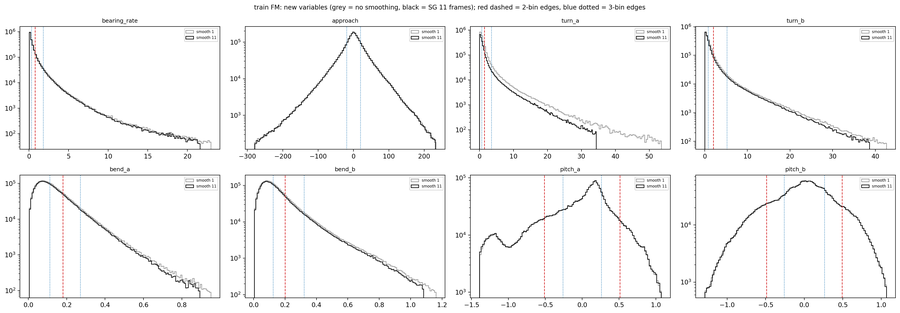

  fig figures/01_extra_distributions__MM__sw1_11__train.png


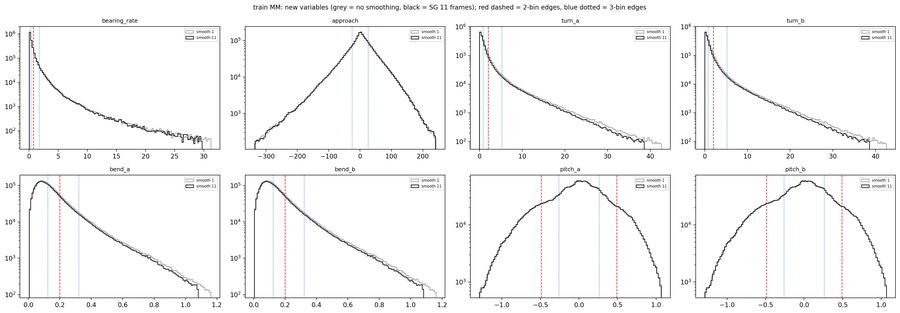

  csv data/01_quantiles__all__sw1_11__train.csv  rows 32
unit  smooth     variable      q5     q25    q50    q75    q90    q95  abs_q50  abs_q75
  FM       1 bearing_rate   0.018   0.110  0.310  0.781  1.818  2.945    0.310    0.781
  FM      11 bearing_rate   0.018   0.109  0.305  0.767  1.789  2.902    0.305    0.767
  FM       1     approach -75.570 -19.154  0.400 20.482 49.973 74.641   19.828   42.088
  FM      11     approach -75.125 -18.837  0.407 20.203 49.610 74.237   19.529   41.725
  FM       1       turn_a   0.044   0.313  0.767  1.629  3.762  6.638    0.767    1.629
  FM      11       turn_a   0.050   0.274  0.647  1.449  3.528  6.281    0.647    1.449
  FM       1       turn_b   0.053   0.385  0.921  2.172  5.384  9.319    0.921    2.172
  FM      11       turn_b   0.060   0.325  0.802  2.028  5.211  8.993    0.802    2.028
  FM       1       bend_a   0.028   0.069  0.114  0.183  0.275  0.351    0.114    0.183
  FM      11       bend_a   0.028   0.068  0.112  0.180  0.270 

In [4]:
# Step 1: distributions of the new variables (train).
L.clear_log("01")


def train_values(w, unit):
    v = np.concatenate([DATA[(w, e, cp)]["vals"][~DATA[(w, e, cp)]["contact"]] for e in TRAIN_EXPERIMENTS for cp in COPIES[unit]])
    return {name: v[np.isfinite(v[:, j]), j].astype(float) for j, name in enumerate(VARS)}


TRAIN_VALS = {(w, u): train_values(w, u) for w in SMOOTH_WINDOWS for u in UNITS}
qrows = []
for unit in UNITS:
    fig, axes = plt.subplots(2, 4, figsize=(20, 7))
    for ax, name in zip(axes.ravel(), P4.VARIABLES_EXTRA):
        for w, col in zip(SMOOTH_WINDOWS, ("0.6", "k")):
            x = TRAIN_VALS[(w, unit)][name]
            lo, hi = np.percentile(x, [0.1, 99.9])
            ax.hist(x[(x >= lo) & (x <= hi)], bins=120, histtype="step", color=col, label=f"smooth {w}")
            qrows.append({"unit": unit, "smooth": w, "variable": name,
                          **{f"q{int(q * 100)}": float(np.quantile(x, q)) for q in (0.05, 0.25, 0.5, 0.75, 0.9, 0.95)},
                          "abs_q50": float(np.quantile(np.abs(x), 0.5)), "abs_q75": float(np.quantile(np.abs(x), 0.75))})
            if w == SMOOTH_WINDOWS[-1]:
                g = GROUP[name]
                if g in SIGNED:
                    for s in (-1, 1):
                        ax.axvline(s * np.quantile(np.abs(x), SIGNED_QUANTILE), color="tab:blue", ls=":", lw=1)
                    if g == "pitch":
                        for s in (-1, 1):
                            ax.axvline(s * np.quantile(np.abs(x), NONNEG_QUANTILES[2][0]), color="tab:red", ls="--", lw=1)
                else:
                    for q in NONNEG_QUANTILES[2]:
                        ax.axvline(np.quantile(x, q), color="tab:red", ls="--", lw=1)
                    for q in NONNEG_QUANTILES[3]:
                        ax.axvline(np.quantile(x, q), color="tab:blue", ls=":", lw=1)
        ax.set_yscale("log")
        ax.set_title(name, fontsize=9)
        ax.legend(fontsize=6)
    fig.suptitle(f"train {unit}: new variables (grey = no smoothing, black = SG {SMOOTH_WINDOWS[-1]} frames); "
                 f"red dashed = 2-bin edges, blue dotted = 3-bin edges", fontsize=10)
    fig.tight_layout()
    p = L.save_fig(fig, "01", "extra_distributions", unit, {"sw": "1_11"}, "train")
    display(IPImage(filename=str(L.thumbs / p.name)))
Q = pd.DataFrame(qrows)
L.save_csv(Q, "01", "quantiles", "all", {"sw": "1_11"}, "train")
print(Q.round(3).to_string(index=False))
L.log("01", "done")

## Step 2 — 各分格方案的占用

**做什么**：每个方案 × 平滑版本 × 单元（FM、MM）：用训练集定边界，给训练、测试的每帧编码成网格状态（contact = 额外一个状态），统计：
- `states_theoretical`：网格状态总数（+ contact）；
- `occupied_train`：训练集实际出现过的状态数；
- `median_frames_per_state`、`mean_frames_per_state`：训练集每个被占用状态的帧数；
- `frames_in_states_lt10_percent`、`..._lt50_percent`：训练集里落在"少于 10 / 50 帧的状态"上的帧占比（这些状态的转移概率几乎估不出来）；
- `graph_edges_tau7`：τ = `TAU_EDGES` 时转移图的边数（片段内，不跨缺口），Infomap 的耗时大致和它成正比；`edges_vs_v3` = 相对 v3 方案的倍数（v3 每次 Infomap 约 3 秒）；
- `test_frames_unseen_percent`：测试集有状态的帧中，落在训练集从未出现过的状态上的比例。

**图** `02_occupancy`：左 = 每个方案被占用的状态数；中 = 落在稀疏状态（< 10 帧）上的训练帧比例；右 = 测试帧落在没见过的状态上的比例。颜色 = 平滑版本。

**输出**：`data/02_occupancy__all__…__all.csv`、`data/02_edges__<scheme>__…__train.json`（各方案的分格边界）。

  json data/02_edges__v3__sw1__train.json


[FM smooth 1 v3] states 16129  occupied 14179  median fr/state 35  edges 172256


  json data/02_edges__A__sw1__train.json


[FM smooth 1 A] states 344065  occupied 121785  median fr/state 4  edges 914247


  json data/02_edges__B__sw1__train.json


[FM smooth 1 B] states 59521393  occupied 869041  median fr/state 1  edges 2110230
  json data/02_edges__C__sw1__train.json


... (27 outputs left out)

[MM smooth 11 D2] states 57345  occupied 40589  median fr/state 9  edges 482341


[MM smooth 11 D3] states 48385  occupied 35555  median fr/state 9  edges 477053


[MM smooth 11 D4] states 14337  occupied 12893  median fr/state 25  edges 307865
  csv data/02_occupancy__all__sw1_11__all.csv  rows 32


  fig figures/02_occupancy__all__sw1_11__all.png


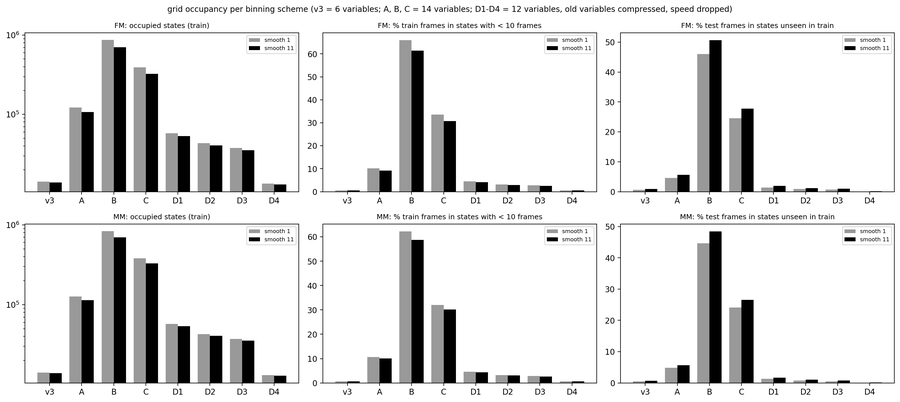

unit  smooth scheme                        bins  states_theoretical  occupied_train  median_frames_per_state  mean_frames_per_state  frames_in_states_lt10_percent  frames_in_states_lt50_percent  graph_edges_tau7  edges_vs_v3  test_frames_unseen_percent
  FM       1     v3                 7x4x8x8x3x3               16129           14179                     35.0                 185.10                           0.57                           5.06            172256         1.00                        0.62
  FM       1      A 7x2x4x4x2x2x2x3x2x2x2x2x2x2              344065          121785                      4.0                  21.55                          10.15                          30.65            914247         5.31                        4.57
  FM       1      B 7x4x6x6x3x3x3x3x3x3x3x3x3x3            59521393          869041                      1.0                   3.02                          65.91                          91.18           2110230        12.25                 

In [5]:
# Step 2: occupancy of every scheme.
L.clear_log("02")
rows = []
for unit in UNITS:
    for w in SMOOTH_WINDOWS:
        for scheme in SCHEMES:
            cols = scheme_vars(scheme)
            edges = edges_for(scheme, TRAIN_VALS[(w, unit)])
            if unit == "FM":
                L.save_json({v: (["abs", e[1].tolist()] if isinstance(e, tuple) else np.asarray(e).tolist()) for v, e in edges.items()},
                            "02", "edges", scheme, {"sw": w}, "train")
            enc = {}
            for set_name, exps in SETS.items():
                st, sg = [], []
                for e in exps:
                    for cp in COPIES[unit]:
                        d = DATA[(w, e, cp)]
                        s, n_states = encode(d["vals"], d["contact"], edges, cols)
                        s[d["seg"] < 0] = -1
                        st.append(s)
                        sg.append(np.where(d["seg"] >= 0, d["seg"] + 10_000_000 * len(sg), -1))
                enc[set_name] = (np.concatenate(st), np.concatenate(sg))
            st, sg = enc["train"]
            has = st >= 0
            uniq, counts = np.unique(st[has], return_counts=True)
            per_frame = counts[np.searchsorted(uniq, st[has])]
            a, b = st[:-TAU_EDGES], st[TAU_EDGES:]
            same = (sg[:-TAU_EDGES] == sg[TAU_EDGES:]) & (sg[:-TAU_EDGES] >= 0) & (a >= 0) & (b >= 0)
            n_edges = len(np.unique(a[same] * np.int64(n_states) + b[same]))
            ts, _ = enc["test"]
            th = ts >= 0
            row = {"unit": unit, "smooth": w, "scheme": scheme, "n_variables": len(cols),
                   "bins": "x".join(str(n_bins(edges[v])) for v in cols), "states_theoretical": n_states,
                   "train_frames_with_state": int(has.sum()), "occupied_train": len(uniq),
                   "occupied_share_percent": 100 * len(uniq) / n_states,
                   "median_frames_per_state": float(np.median(counts)), "mean_frames_per_state": float(counts.mean())}
            for k in SPARSE_FRAMES:
                row[f"frames_in_states_lt{k}_percent"] = 100 * float((per_frame < k).mean())
            row["graph_edges_tau7"] = n_edges
            row["test_frames_unseen_percent"] = 100 * float((~np.isin(ts[th], uniq)).mean())
            rows.append(row)
            print(f"[{unit} smooth {w} {scheme}] states {n_states}  occupied {len(uniq)}  median fr/state {np.median(counts):.0f}  "
                  f"edges {n_edges}")
OCC = pd.DataFrame(rows)
ref = OCC[OCC["scheme"] == "v3"].set_index(["unit", "smooth"])["graph_edges_tau7"]
OCC["edges_vs_v3"] = [r.graph_edges_tau7 / ref.loc[(r.unit, r.smooth)] for r in OCC.itertuples()]
L.save_csv(OCC, "02", "occupancy", "all", {"sw": "1_11"}, "all")

fig, axes = plt.subplots(len(UNITS), 3, figsize=(16, 3.6 * len(UNITS)), squeeze=False)
names = list(SCHEMES)
x = np.arange(len(names))
for r_, unit in enumerate(UNITS):
    for k, (col, lab) in enumerate((("occupied_train", "occupied states (train)"),
                                    ("frames_in_states_lt10_percent", "% train frames in states with < 10 frames"),
                                    ("test_frames_unseen_percent", "% test frames in states unseen in train"))):
        ax = axes[r_, k]
        for j, w in enumerate(SMOOTH_WINDOWS):
            d = OCC[(OCC["unit"] == unit) & (OCC["smooth"] == w)].set_index("scheme").loc[names]
            ax.bar(x + (j - 0.5) * 0.38, d[col], width=0.38, color=("0.6", "k")[j], label=f"smooth {w}")
        ax.set_xticks(x, names)
        if k == 0:
            ax.set_yscale("log")
        ax.set_title(f"{unit}: {lab}", fontsize=9)
        ax.legend(fontsize=7)
fig.suptitle("grid occupancy per binning scheme (v3 = 6 variables; A, B, C = 14 variables; D1-D4 = 12 variables, "
             "old variables compressed, speed dropped)", fontsize=10)
fig.tight_layout()
p = L.save_fig(fig, "02", "occupancy", "all", {"sw": "1_11"}, "all")
display(IPImage(filename=str(L.thumbs / p.name)))
show = ["unit", "smooth", "scheme", "bins", "states_theoretical", "occupied_train", "median_frames_per_state",
        "mean_frames_per_state", "frames_in_states_lt10_percent", "frames_in_states_lt50_percent",
        "graph_edges_tau7", "edges_vs_v3", "test_frames_unseen_percent"]
print(OCC[show].round(2).to_string(index=False))
L.log("02", "done")

## Step 3 — 文件清单

In [6]:
print("output folder:", L.root)
for sub in ("figures", "data"):
    files = sorted(p.name for p in (L.root / sub).iterdir())
    print(f"\n{sub}/ ({len(files)} files)")
    for f in files:
        print("  ", f)

output folder: \\bucket.oist.jp\bucket\StephensU\medaka\runs\behavior_features\outputs\20261108_pair_state14d_occupancy_v4

figures/ (3 files)
   01_extra_distributions__FM__sw1_11__train.png
   01_extra_distributions__MM__sw1_11__train.png
   02_occupancy__all__sw1_11__all.png

data/ (20 files)
   00_gap_table__all__sw1_11__all.csv
   01_quantiles__all__sw1_11__train.csv
   02_edges__A__sw11__train.json
   02_edges__A__sw1__train.json
   02_edges__B__sw11__train.json
   02_edges__B__sw1__train.json
   02_edges__C__sw11__train.json
   02_edges__C__sw1__train.json
   02_edges__D1__sw11__train.json
   02_edges__D1__sw1__train.json
   02_edges__D2__sw11__train.json
   02_edges__D2__sw1__train.json
   02_edges__D3__sw11__train.json
   02_edges__D3__sw1__train.json
   02_edges__D4__sw11__train.json
   02_edges__D4__sw1__train.json
   02_edges__v3__sw11__train.json
   02_edges__v3__sw1__train.json
   02_occupancy__all__sw1_11__all.csv
   run_log.json
